# 01 · Estructuras de datos en Python

Los bloques con los que se construye cualquier programa en Python: las cuatro colecciones básicas, los
contenedores especializados de la biblioteca estándar, las funciones, un primer vistazo a las clases, las
comprensiones y el manejo de errores. Cada ejemplo es corto y ejecutable; modifícalo y vuelve a ejecutarlo.

**Aprenderás**
1. Listas, tuplas, diccionarios y conjuntos, y cuándo usar cada uno
2. El módulo `collections`: `deque`, `Counter`, `defaultdict`, `namedtuple`
3. Funciones: argumentos por defecto, `*args`, `**kwargs`, lambdas
4. Clases en cinco minutos (el módulo 05 profundiza mucho más)
5. Comprensiones y generadores
6. Excepciones
7. Por qué importa la estructura elegida: medir la velocidad de búsqueda

## 1. Listas
Ordenadas, **mutables** y admiten duplicados. El contenedor por defecto para "una secuencia de cosas".

In [1]:
fruits = ["apple", "banana", "cherry"]
fruits.append("date")             # añadir al final
fruits.insert(1, "apricot")       # añadir en una posición
fruits.remove("banana")           # quitar el primer valor que coincida
last = fruits.pop()               # quitar y devolver el último elemento
print(fruits, "| extraído:", last)

# rebanadas: [inicio:fin:paso], el fin no se incluye
nums = list(range(10))
print(nums[2:5], nums[::2], nums[::-1])

# ordenar: sorted() devuelve una lista nueva, .sort() ordena en el sitio
words = ["pear", "Fig", "apple"]
print(sorted(words), sorted(words, key=str.lower), sorted(words, key=len, reverse=True))

['apple', 'apricot', 'cherry'] | extraído: date
[2, 3, 4] [0, 2, 4, 6, 8] [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
['Fig', 'apple', 'pear'] ['apple', 'Fig', 'pear'] ['apple', 'pear', 'Fig']


## 2. Tuplas
Ordenadas e **inmutables**. Úsalas para grupos fijos de valores (un punto, una fila de una base de datos) y
para devolver varios valores desde una función. Al ser inmutables, pueden ser claves de un diccionario o
elementos de un conjunto.

In [2]:
point = (3, 4)
single = ("only_one",)            # la coma final la convierte en tupla
x, y = point                      # desempaquetado
print(point, single, x, y)

def min_max(values):
    return min(values), max(values)   # devuelve una tupla

lo, hi = min_max([7, 2, 9, 4])
print(lo, hi)

first, *middle, last = [1, 2, 3, 4, 5]   # desempaquetado extendido
print(first, middle, last)

(3, 4) ('only_one',) 3 4
2 9
1 [2, 3, 4] 5


## 3. Diccionarios
Pares clave-valor, mutables y ordenados por inserción desde Python 3.7. Buscar por clave es rápido, sea cual
sea el tamaño del diccionario.

In [3]:
person = {"name": "Alice", "age": 30, "city": "Berlin"}
person["age"] = 31                       # actualizar
person["email"] = "alice@example.com"    # añadir
print(person.get("phone", "n/d"))        # acceso seguro con valor por defecto
for key, value in person.items():
    print(f"{key:>6}: {value}")

# combinar diccionarios y comprensiones de diccionario
defaults = {"city": "Unknown", "active": True}
merged = defaults | person               # gana el de la derecha (Python 3.9+)
squares = {n: n * n for n in range(5)}
print(merged, squares)

n/d
  name: Alice
   age: 31
  city: Berlin
 email: alice@example.com
{'city': 'Berlin', 'active': True, 'name': 'Alice', 'age': 31, 'email': 'alice@example.com'} {0: 0, 1: 1, 2: 4, 3: 9, 4: 16}


## 4. Conjuntos
Sin orden, mutables y con elementos **únicos**. Ideales para comprobar pertenencia y eliminar duplicados.

In [4]:
a, b = {1, 2, 3}, {3, 4, 5}
print(a | b, a & b, a - b, a ^ b)        # unión, intersección, diferencia, diferencia simétrica

nums = [1, 2, 2, 3, 3, 3]
print(sorted(set(nums)))                 # deduplicar (los conjuntos no guardan orden: ordena si lo necesitas)
print(3 in a, frozenset(a))              # frozenset: conjunto inmutable, sirve como clave de diccionario

{1, 2, 3, 4, 5} {3} {1, 2} {1, 2, 4, 5}
[1, 2, 3]
True frozenset({1, 2, 3})


## 5. Contenedores especializados: `collections`
La biblioteca estándar trae estructuras listas para patrones comunes. Usarlas acorta el código y a menudo
lo hace más rápido.

| Estructura | Úsala para |
|---|---|
| `deque` | colas y ventanas deslizantes: añadir y quitar rápido por **ambos** extremos |
| `Counter` | contar cosas |
| `defaultdict` | agrupar sin comprobaciones del tipo "si la clave no está en el diccionario" |
| `namedtuple` | registros ligeros con campos con nombre |
| `heapq` (módulo) | obtener siempre el elemento más pequeño: colas de prioridad, los k mejores |

In [5]:
from collections import deque, Counter, defaultdict, namedtuple
import heapq

window = deque(maxlen=3)                 # guarda solo los 3 últimos elementos
for reading in [10, 12, 11, 15, 14]:
    window.append(reading)
print("últimas 3 lecturas:", list(window), "media:", sum(window) / len(window))

text = "the quick brown fox jumps over the lazy dog the end"
print(Counter(text.split()).most_common(2))

by_letter = defaultdict(list)
for word in ["apple", "avocado", "banana", "blueberry", "cherry"]:
    by_letter[word[0]].append(word)
print(dict(by_letter))

City = namedtuple("City", ["name", "population_m"])
cities = [City("Tokyo", 37.4), City("Delhi", 32.9), City("Shanghai", 29.2), City("Madrid", 6.8)]
print(heapq.nlargest(2, cities, key=lambda c: c.population_m))

últimas 3 lecturas: [11, 15, 14] media: 13.333333333333334
[('the', 3), ('quick', 1)]
{'a': ['apple', 'avocado'], 'b': ['banana', 'blueberry'], 'c': ['cherry']}
[City(name='Tokyo', population_m=37.4), City(name='Delhi', population_m=32.9)]


## 6. Funciones
Bloques de código reutilizables. Las anotaciones de tipo documentan qué entra y qué sale; Python no las
comprueba al ejecutar, pero los editores y herramientas como `mypy` sí las usan.

In [6]:
def greet(name: str, greeting: str = "Hello") -> str:
    return f"{greeting}, {name}!"

print(greet("Alice"), greet("Bob", greeting="Hi"))

def total(*args: float) -> float:          # cualquier número de argumentos posicionales
    return sum(args)

def describe(**kwargs) -> str:             # cualquier número de argumentos con nombre
    return ", ".join(f"{k}={v}" for k, v in kwargs.items())

print(total(1, 2, 3), "|", describe(colour="red", size="M"))

square = lambda n: n ** 2                   # pequeña función anónima
print(list(map(square, [1, 2, 3])), sorted(["bb", "a", "ccc"], key=lambda s: -len(s)))

Hello, Alice! Hi, Bob!
6 | colour=red, size=M
[1, 4, 9] ['ccc', 'bb', 'a']


**Una trampa clásica: argumentos por defecto mutables.** El valor por defecto se crea una sola vez, al
definir la función, no en cada llamada.

In [7]:
def add_item_bad(item, items=[]):
    items.append(item)
    return items

def add_item_good(item, items=None):
    items = [] if items is None else items
    items.append(item)
    return items

print(add_item_bad("a"), add_item_bad("b"))     # se reutiliza la misma lista: ['a', 'b'] dos veces
print(add_item_good("a"), add_item_good("b"))

['a', 'b'] ['a', 'b']
['a'] ['b']


## 7. Clases en cinco minutos
Una clase es un plano, un objeto es una instancia de ella y los métodos son funciones que pertenecen a la
clase. El módulo 05 trata la programación orientada a objetos a fondo; esto es lo justo para leer código que
la usa.

In [8]:
class Dog:
    species = "Canis familiaris"            # atributo de clase: compartido por todos los perros

    def __init__(self, name: str, age: int):
        self.name = name                    # atributos de instancia: uno por perro
        self.age = age

    def speak(self) -> str:
        return f"{self.name} dice guau"

    def __repr__(self) -> str:              # cómo se imprime el objeto
        return f"Dog(name={self.name!r}, age={self.age})"

rex = Dog("Rex", 4)
print(rex, rex.speak(), Dog.species)

Dog(name='Rex', age=4) Rex dice guau Canis familiaris


## 8. Comprensiones y generadores
Las comprensiones construyen una colección en una línea legible. Un **generador** produce los valores bajo
demanda, uno a uno, así que apenas usa memoria aunque sean millones de elementos. La idea reaparece en el
módulo 03.

In [9]:
import sys

squares = [n ** 2 for n in range(10) if n % 2 == 0]
pairs = [(x, y) for x in range(3) for y in "ab"]
print(squares, pairs)

big_list = [n for n in range(1_000_000)]
big_gen = (n for n in range(1_000_000))
print(f"lista: {sys.getsizeof(big_list) / 1e6:.1f} MB, generador: {sys.getsizeof(big_gen)} bytes")
print("suma desde el generador:", sum(big_gen))

def countdown(n):
    while n > 0:
        yield n          # 'yield' convierte esta función en un generador
        n -= 1

print(list(countdown(5)))

[0, 4, 16, 36, 64] [(0, 'a'), (0, 'b'), (1, 'a'), (1, 'b'), (2, 'a'), (2, 'b')]
lista: 8.4 MB, generador: 192 bytes


suma desde el generador: 499999500000
[5, 4, 3, 2, 1]


## 9. Excepciones
Gestiona los errores que esperas y deja que los inesperados salgan a la luz. `else` solo se ejecuta si nada
falló; `finally` se ejecuta siempre (limpieza).

In [10]:
def divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print("no se puede dividir entre cero")
        return None
    except TypeError as e:
        print("entrada no válida:", e)
        return None
    else:
        return result
    finally:
        print(f"divide({a!r}, {b!r}) terminado")

print(divide(10, 2), divide(1, 0), divide("a", 1))

class InsufficientFunds(Exception):
    '''Una excepción propia deja explícito el fallo a quien llama.'''

try:
    raise InsufficientFunds("saldo 10, solicitado 50")
except InsufficientFunds as e:
    print("capturada:", e)

divide(10, 2) terminado
no se puede dividir entre cero
divide(1, 0) terminado
entrada no válida: unsupported operand type(s) for /: 'str' and 'int'
divide('a', 1) terminado
5.0 None None
capturada: saldo 10, solicitado 50


## 10. Por qué importa la estructura elegida
Comprobar si un elemento está **en** una lista la recorre elemento a elemento (el tiempo crece con el tamaño,
O(n)). Un conjunto o un diccionario usa hashing y responde en aproximadamente el mismo tiempo sea cual sea
su tamaño (O(1) en promedio). Medido:

n=    1,000  lista:       13.1 µs   conjunto:   0.15 µs
n=   10,000  lista:      132.6 µs   conjunto:   0.14 µs
n=  100,000  lista:     1370.3 µs   conjunto:   0.15 µs
n=1,000,000  lista:    14007.4 µs   conjunto:   0.16 µs


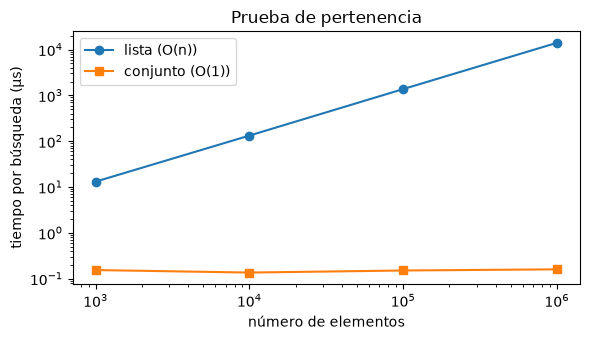

In [11]:
import timeit
import matplotlib.pyplot as plt

sizes = [1_000, 10_000, 100_000, 1_000_000]
t_list, t_set = [], []
for n in sizes:
    data_list = list(range(n))
    data_set = set(data_list)
    target = n - 1                          # peor caso para la lista: el último elemento
    t_list.append(timeit.timeit(lambda: target in data_list, number=50) / 50 * 1e6)
    t_set.append(timeit.timeit(lambda: target in data_set, number=50) / 50 * 1e6)

for n, a, b in zip(sizes, t_list, t_set):
    print(f"n={n:>9,}  lista: {a:10.1f} µs   conjunto: {b:6.2f} µs")

plt.figure(figsize=(6, 3.5))
plt.loglog(sizes, t_list, "o-", label="lista (O(n))")
plt.loglog(sizes, t_set, "s-", label="conjunto (O(1))")
plt.xlabel("número de elementos"); plt.ylabel("tiempo por búsqueda (µs)"); plt.legend(); plt.title("Prueba de pertenencia")
plt.tight_layout(); plt.show()

| Operación | list | tuple | dict | set |
|---|---|---|---|---|
| ordenado | sí | sí | sí (inserción) | no |
| mutable | sí | no | sí | sí |
| duplicados | sí | sí | claves únicas | no |
| `x in c` | O(n) | O(n) | O(1) en claves | O(1) |
| uso típico | secuencias | registros fijos | búsquedas por clave | pertenencia, deduplicar |

## Ejercicios
1. Dada una lista de palabras, devuelve las cinco más frecuentes con su recuento (una línea con `Counter`).
2. Agrupa una lista de tuplas `(alumno, nota)` en un diccionario `nota -> [alumnos]` con `defaultdict`.
3. Escribe un generador `fibonacci()` que produzca la sucesión indefinidamente e imprime los 15 primeros valores con `itertools.islice`.
4. Repite el experimento de tiempos con un `dict` y una `tuple`. ¿Cuál se comporta como una lista y cuál como un conjunto?